MSBD 566 – Predictive Modeling and Analytics


 Assignment 2: Validation, Tuning and Honest Evaluation

Keimora Wright

*I used AI to help understand concepts and improve accuracy.

The goal of this project is to predict whether a speech recording can accurately detect Parkinson's disease. This prediction could be used by healthcare providers and researchers as a screening tool to help identify patients who may need further clinical evaluation to potentially diagnose them with Parkinson's disease. I will use ROC-AUC as the primary success metric, however the goal is to report a number that can be trusted. 

Part 1. Understand the Data

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "pd_speech_features.csv",
    header=1
)

print(df.shape)

df.head()

(756, 755)


,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
0,0,1,0.85247,0.71826,0.57227,240,239,0.008064,0.000087,0.00218,...,1.5620,2.6445,3.8686,4.2105,5.1221,4.4625,2.6202,3.0004,18.9405,1
1,0,1,0.76686,0.69481,0.53966,234,233,0.008258,0.000073,0.00195,...,1.5589,3.6107,23.5155,14.1962,11.0261,9.5082,6.5245,6.3431,45.1780,1
2,0,1,0.85083,0.67604,0.58982,232,231,0.008340,0.000060,0.00176,...,1.5643,2.3308,9.4959,10.7458,11.0177,4.8066,2.9199,3.1495,4.7666,1
3,1,0,0.41121,0.79672,0.59257,178,177,0.010858,0.000183,0.00419,...,3.7805,3.5664,5.2558,14.0403,4.2235,4.6857,4.8460,6.2650,4.0603,1
4,1,0,0.32790,0.79782,0.53028,236,235,0.008162,0.002669,0.00535,...,6.1727,5.8416,6.0805,5.7621,7.7817,11.6891,8.2103,5.0559,6.1164,1


In [3]:
print("Shape:", df.shape)

print("\nMissing Values")
print(df.isnull().sum().sum())

print("\nDuplicate Rows")
print(df.duplicated().sum())

print("\nUnique Subjects")
print(df["id"].nunique())

print("\nClass Counts")
print(df["class"].value_counts())

print("\nClass Percentages")
print(df["class"].value_counts(normalize=True))

subject_counts = df["id"].value_counts()

print("\nRecordings Per Subject")
print(subject_counts.describe())

Shape: (756, 755)

Missing Values
0

Duplicate Rows
1

Unique Subjects
252

Class Counts
class
1    564
0    192
Name: count, dtype: int64

Class Percentages
class
1    0.746032
0    0.253968
Name: proportion, dtype: float64

Recordings Per Subject
count    252.0
mean       3.0
std        0.0
min        3.0
25%        3.0
50%        3.0
75%        3.0
max        3.0
Name: count, dtype: float64


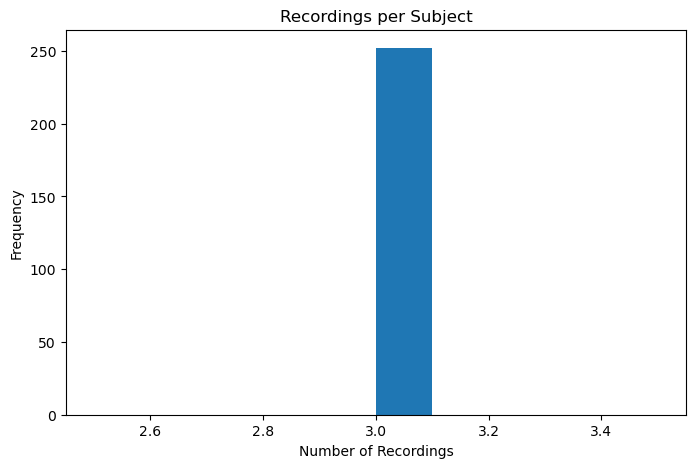

In [4]:
import matplotlib.pyplot as plt

subject_counts = df["id"].value_counts()

plt.figure(figsize=(8,5))

plt.hist(subject_counts)

plt.title("Recordings per Subject")

plt.xlabel("Number of Recordings")

plt.ylabel("Frequency")

plt.show()

In [5]:
majority_accuracy = (
    df["class"]
      .value_counts(normalize=True)
      .max()
)

print(
    f"Majority Baseline Accuracy = {majority_accuracy:.4f}"
)

Majority Baseline Accuracy = 0.7460


In [6]:
X = df.drop(
    columns=["id", "gender", "class"]
)

y = df["class"]

groups = df["id"]

In [7]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        X,
        y,
        groups
    )
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

In [8]:
overlap = set(
    groups_train
).intersection(
    set(groups_test)
)

print(
    "Overlap Subjects:",
    len(overlap)
)

Overlap Subjects: 0


Q1.

The unit of observation is a single speech recording because each row in the dataset represents one recording and its extracted features. The unit of independence is the subject, since each of the 252 subjects contributes three recordings. Because recordings from the same person are not independent, the data should be split by subject rather than by individual recording to prevent data leakage.

Q2.

The majority-class baseline achieves an accuracy of 74.6%. Because the dataset is somewhat imbalanced, I will focus on ROC-AUC as the primary evaluation metric, since it measures how well the model distinguishes between classes across different thresholds. I will also examine precision and recall to better understand classification performance. The visualization shows that each subject contributes three recordings, which motivates the decision to use grouped train/test splitting and grouped cross-validation based on subject ID.

Part 2. Splitting and Leakage

I think StratifiedKFold will give higher ROC-AUC scores than StratifiedGroupKFold. Each person has three recordings, so StratifiedKFold may place recordings from the same person in both the training and validation sets. This could make the model appear more accurate because it has already seen similar data from that person. StratifiedGroupKFold keeps all recordings from the same person together, so I expect the results to be a little lower but more realistic.

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold,
    cross_val_score
)

# Logistic Regression Pipeline
log_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

# Cross-validation methods
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [10]:
log_skf = cross_val_score(
    log_pipe,
    X_train,
    y_train,
    cv=skf,
    scoring="roc_auc"
)

log_sgkf = cross_val_score(
    log_pipe,
    X_train,
    y_train,
    groups=groups_train,
    cv=sgkf,
    scoring="roc_auc"
)

print("Logistic Regression")
print("StratifiedKFold Scores:", log_skf)
print("Mean AUC:", log_skf.mean())

print("\nStratifiedGroupKFold Scores:", log_sgkf)
print("Mean AUC:", log_sgkf.mean())

Logistic Regression
StratifiedKFold Scores: [0.81282051 0.78388278 0.91684982 0.90592593 0.87259259]
Mean AUC: 0.8584143264143265

StratifiedGroupKFold Scores: [0.77168459 0.76041667 0.70811564 0.73875661 0.95459976]
Mean AUC: 0.7867146536876792


In [11]:
for k in [3, 5, 10]:

    cv = StratifiedGroupKFold(
        n_splits=k,
        shuffle=True,
        random_state=42
    )

    scores = cross_val_score(
        log_pipe,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv,
        scoring="roc_auc"
    )

    print(
        f"k = {k}: "
        f"Mean AUC = {scores.mean():.4f}, "
        f"Std = {scores.std():.4f}"
    )

k = 3: Mean AUC = 0.7773, Std = 0.0092
k = 5: Mean AUC = 0.7867, Std = 0.0867
k = 10: Mean AUC = 0.7462, Std = 0.1023


Q3. 

The Logistic Regression model achieved a mean ROC-AUC of 0.8541 and StratifiedGroupKFold achieved 0.7867. The two splitters disagree because StratifiedKFold can place recordings from the same subject in both the training and validation folds. Since each subject contributes three recordings, the model may learn subject-specific patterns and achieve artificially high performance. StratifiedGroupKFold prevents this by keeping all recordings from a subject together in one fold. I would report the 0.7867 estimate because it provides a more realistic measure of performance on unseen subjects.

Q4. 

(a) StratifiedGroupKFold is preferred because the dataset is imbalanced, with approximately 74.6% Parkinson's cases and 25.4% healthy controls. With only 252 subjects, some folds created by plain GroupKFold could have very different class distributions, leading to unreliable performance estimates. StratifiedGroupKFold maintains class balance across folds while also keeping subjects together.

(b) Standard leave-one-out cross-validation would not be valid because it leaves out only one recording at a time, allowing other recordings from the same subject to remain in the training set. A valid approach would be leave-one-subject-out cross-validation, where all recordings from one subject are held out together. This prevents subject-level leakage and gives a more realistic evaluation.

Part 3. Leakage inside the pipeline

In [12]:
from sklearn.feature_selection import SelectKBest, f_classif

# Create random noise features
rng = np.random.RandomState(42)

X_noise = pd.DataFrame(
    rng.normal(size=(len(X_train), 500))
)

print(X_noise.shape)

(603, 500)


In [13]:
selector = SelectKBest(
    score_func=f_classif,
    k=20
)

# Leakage occurs here
X_selected = selector.fit_transform(
    X_noise,
    y_train
)

wrong_scores = cross_val_score(
    log_pipe,
    X_selected,
    y_train,
    groups=groups_train,
    cv=sgkf,
    scoring="roc_auc"
)

print("Wrong Way AUC Scores:")
print(wrong_scores)

print("Mean AUC:")
print(wrong_scores.mean())

Wrong Way AUC Scores:
[0.64516129 0.66102431 0.79380007 0.71891534 0.6861808 ]
Mean AUC:
0.7010163627831986


In [14]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

noise_pipeline = Pipeline([
    ("select", SelectKBest(
        score_func=f_classif,
        k=20
    )),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

correct_scores = cross_val_score(
    noise_pipeline,
    X_noise,
    y_train,
    groups=groups_train,
    cv=sgkf,
    scoring="roc_auc"
)

print("Pipeline AUCs:", correct_scores)
print("Mean AUC:", correct_scores.mean())

Pipeline AUCs: [0.40573477 0.42491319 0.53152212 0.45667989 0.47232178]
Mean AUC: 0.45823435150563674


Q6.

A model trained on pure random noise should achieve an AUC close to 0.50 because the features contain no real information about the target variable. In this exercise, the leaky approach produced a mean AUC of 0.7010, while the pipeline approach produced a mean AUC of 0.4582, which is much closer to what would be expected from random noise. Information leaked in part (a) because SelectKBest was fit on the entire dataset before cross-validation. This allowed information from the validation folds to influence which features were selected, causing the model to appear much better than it actually was.

Q7.

Two other preprocessing steps that carry the same risk are feature scaling and missing value imputation. For feature scaling, the scaler must be fit only on the training data within each cross-validation fold and then applied to the validation data. For missing value imputation, statistics such as the mean or median must also be calculated using only the training portion of each fold. Both steps should be placed inside a pipeline so they occur after the data has been split into training and validation sets.

Part 4. Bias, variance, regularization

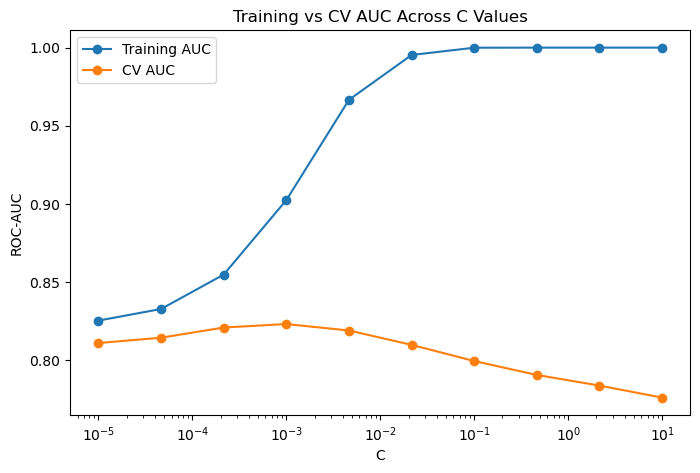

In [15]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

import numpy as np
import matplotlib.pyplot as plt

c_values = np.logspace(-5, 1, 10)

train_auc = []
cv_auc = []

for c in c_values:

    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            penalty="l2",
            C=c,
            max_iter=5000,
            random_state=42
        ))
    ])

    results = cross_validate(
        pipe,
        X_train,
        y_train,
        groups=groups_train,
        cv=sgkf,
        scoring="roc_auc",
        return_train_score=True
    )

    train_auc.append(results["train_score"].mean())
    cv_auc.append(results["test_score"].mean())

plt.figure(figsize=(8,5))

plt.semilogx(
    c_values,
    train_auc,
    marker="o",
    label="Training AUC"
)

plt.semilogx(
    c_values,
    cv_auc,
    marker="o",
    label="CV AUC"
)

plt.xlabel("C")
plt.ylabel("ROC-AUC")
plt.title("Training vs CV AUC Across C Values")
plt.legend()

plt.show()

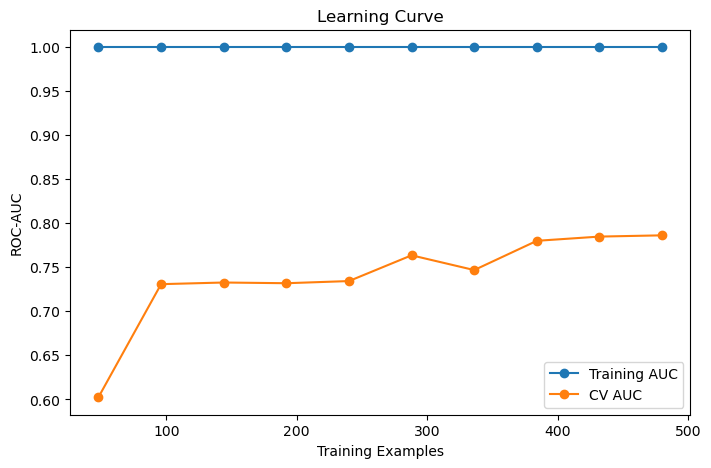

In [16]:
best_c = 1
from sklearn.model_selection import learning_curve

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        penalty="l2",
        C=best_c,
        max_iter=5000,
        random_state=42
    ))
])

train_sizes, train_scores, test_scores = learning_curve(
    pipe,
    X_train,
    y_train,
    groups=groups_train,
    cv=sgkf,
    scoring="roc_auc",
    train_sizes=np.linspace(0.1, 1.0, 10)
)

plt.figure(figsize=(8,5))

plt.plot(
    train_sizes,
    train_scores.mean(axis=1),
    marker="o",
    label="Training AUC"
)

plt.plot(
    train_sizes,
    test_scores.mean(axis=1),
    marker="o",
    label="CV AUC"
)

plt.xlabel("Training Examples")

plt.ylabel("ROC-AUC")

plt.title("Learning Curve")

plt.legend()

plt.show()

In [23]:
results = []

for penalty in ["l1", "l2", "elasticnet"]:

    if penalty == "elasticnet":
        model = LogisticRegression(
            penalty="elasticnet",
            solver="saga",
            l1_ratio=0.5,
            C=1,
            max_iter=5000,
            random_state=42
        )

    elif penalty == "l1":
        model = LogisticRegression(
            penalty="l1",
            solver="saga",
            C=1,
            max_iter=5000,
            random_state=42
        )

    else:
        model = LogisticRegression(
            penalty="l2",
            C=1,
            max_iter=5000,
            random_state=42
        )

    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    auc = cross_val_score(
        pipe,
        X_train,
        y_train,
        groups=groups_train,
        cv=sgkf,
        scoring="roc_auc"
    ).mean()

    pipe.fit(X_train, y_train)

    coef = pipe.named_steps["model"].coef_[0]

    nonzero = np.sum(coef != 0)

    results.append(
        [penalty, auc, nonzero]
    )

results_df = pd.DataFrame(
    results,
    columns=["Penalty", "CV_AUC", "Nonzero_Coefficients"]
)

print(results_df)

      Penalty    CV_AUC  Nonzero_Coefficients
0          l1  0.805427                   223
1          l2  0.786715                   752
2  elasticnet  0.807391                   346


In [51]:
l2_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        penalty="l2",
        C=1,
        max_iter=5000,
        random_state=42
    ))
])

l2_pipe.fit(X_train, y_train)

coef = l2_pipe.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coef
})

coef_df["Absolute"] = coef_df["Coefficient"].abs()

top3 = (
    coef_df
    .sort_values("Absolute", ascending=False)
    .head(3)
    .copy()
)

top3["Odds_Ratio"] = np.exp(top3["Coefficient"])

print(top3[["Feature", "Coefficient", "Odds_Ratio"]])

                       Feature  Coefficient  Odds_Ratio
748  tqwt_kurtosisValue_dec_33     0.760391    2.139113
94       mean_11th_delta_delta    -0.726603    0.483549
62          mean_MFCC_7th_coef     0.693170    2.000045


Q8.

On the C plot, underfitting occurs at very small C values, where both the training and CV AUC are low because the model is too heavily regularized. Overfitting occurs at larger C values, where the training AUC gets close to 1.0 while the CV AUC decreases. At C = 1, the large gap between training AUC and CV AUC suggests high variance, meaning the model fits the training data better than it generalizes to new data. The learning curve shows that more subjects could still help improve performance, but the large number of features is also limiting performance.

Q9.

Strong regularization helps because there are many more features (752) than subjects (252), which increases the risk of overfitting. Regularization shrinks coefficient values and helps the model focus on the most useful patterns. The features selected by L1 should not be over-interpreted because many features are correlated, so a different sample of data could produce a different set of selected features. For example, the feature twqt_kurtosisValue_dec_33 has an odds ratio of about 2.14, meaning a one-standard-deviation increase in this feature is associated with about twice the odds of being classified as Parkinson’s disease. However, this does not mean the feature causes Parkinson’s disease.

Part 5. Tuning and honest model selection

In [39]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    StratifiedGroupKFold,
    GridSearchCV
)
from sklearn.metrics import roc_auc_score
import numpy as np
import time

outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

log_results = []

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X_train, y_train, groups_train), start=1
):

    X_tr = X_train.iloc[train_idx]
    X_te = X_train.iloc[test_idx]

    y_tr = y_train.iloc[train_idx]
    y_te = y_train.iloc[test_idx]

    groups_tr = groups_train.iloc[train_idx]

    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=42
        ))
    ])

    grid = {
        "model__C": [0.001, 0.01, 0.1, 1, 10]
    }

    inner_cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    search = GridSearchCV(
        pipe,
        grid,
        cv=inner_cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    start = time.time()

    search.fit(
        X_tr,
        y_tr,
        groups=groups_tr
    )

    runtime = time.time() - start

    probs = search.best_estimator_.predict_proba(
        X_te
    )[:,1]

    auc = roc_auc_score(
        y_te,
        probs
    )

    log_results.append([
        fold,
        auc,
        search.best_score_,
        search.best_params_,
        runtime
    ])

    print(
        f"Fold {fold}: "
        f"AUC={auc:.4f}"
    )

log_df = pd.DataFrame(
    log_results,
    columns=[
        "Fold",
        "Outer_AUC",
        "Naive_AUC",
        "Best_Params",
        "Runtime"
    ]
)

print(log_df)

print(
    "\nMean Outer AUC:",
    log_df["Outer_AUC"].mean()
)

print(
    "Std Outer AUC:",
    log_df["Outer_AUC"].std()
)

Fold 1: AUC=0.8283
Fold 2: AUC=0.8186
Fold 3: AUC=0.7544
Fold 4: AUC=0.7493
Fold 5: AUC=0.9646
   Fold  Outer_AUC  Naive_AUC          Best_Params   Runtime
0     1   0.828315   0.816790  {'model__C': 0.001}  8.102847
1     2   0.818576   0.810868  {'model__C': 0.001}  8.405088
2     3   0.754441   0.819368  {'model__C': 0.001}  8.613170
3     4   0.749339   0.847385  {'model__C': 0.001}  8.301641
4     5   0.964556   0.776394  {'model__C': 0.001}  8.298735

Mean Outer AUC: 0.8230454681109343
Std Outer AUC: 0.08690834210395293


In [42]:
params = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5]
}

search = RandomizedSearchCV(
    rf,
    params,
    n_iter=5,      # reduced from 10
    scoring="roc_auc",
    cv=inner_cv,
    random_state=42,
    n_jobs=-1
)

In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

rf = RandomForestClassifier(random_state=42)

params = {
    "n_estimators": [50, 100],
    "max_depth": [5, 10],
}

search = RandomizedSearchCV(
    rf,
    params,
    n_iter=2,
    cv=3,
    scoring="roc_auc",
    random_state=42
)

search.fit(X_train, y_train)

print("Best Score:", search.best_score_)
print("Best Params:", search.best_params_)

Best Score: 0.8063134657836645
Best Params: {'n_estimators': 100, 'max_depth': 5}


In [50]:
from sklearn.svm import SVC

from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingRandomSearchCV

In [45]:
svm_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        probability=True,
        random_state=42
    ))
])

In [46]:
svm_params = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__gamma": ["scale", "auto"]
}

In [49]:
svm_df = pd.DataFrame(
    svm_results,
    columns=[
        "Fold",
        "Outer_AUC",
        "Naive_AUC",
        "Best_Params",
        "Runtime"
    ]
)

print(svm_df)

print("\nMean Outer AUC:",
      svm_df["Outer_AUC"].mean())

print("Std Outer AUC:",
      svm_df["Outer_AUC"].std())

print("Mean Naive AUC:",
      svm_df["Naive_AUC"].mean())

print("Average Runtime:",
      svm_df["Runtime"].mean())

   Fold  Outer_AUC  Naive_AUC                                 Best_Params  \
0     1   0.798566   0.755521    {'model__gamma': 'scale', 'model__C': 1}   
1     2   0.849392   0.740147  {'model__gamma': 'auto', 'model__C': 0.01}   
2     3   0.777778   0.767123    {'model__gamma': 'auto', 'model__C': 10}   
3     4   0.738426   0.818478    {'model__gamma': 'auto', 'model__C': 10}   
4     5   0.948228   0.718100    {'model__gamma': 'auto', 'model__C': 10}   

     Runtime  
0  17.683789  
1  18.589809  
2  18.906785  
3  18.601948  
4  18.913594  

Mean Outer AUC: 0.8224780341497411
Std Outer AUC: 0.08088885040388313
Mean Naive AUC: 0.7598738957243577
Average Runtime: 18.539185094833375


Q10.

Q10.

The Logistic Regression model had very similar naive and nested CV scores, while the SVM actually had a lower naive score (0.7599) than its nested outer AUC (0.8225). A small gap does not mean nested CV was unnecessary. Nested CV is still important because it provides an unbiased estimate of performance after hyperparameter tuning. I would expect larger gaps when the search space is larger, the dataset is smaller, or the model is more prone to overfitting during tuning.

Q11.

Logistic Regression (0.8230) and SVM (0.8225) achieved nearly identical mean outer AUC scores. The difference between the models is much smaller than the fold-to-fold variation (standard deviations of about 0.08-0.09), so there is not strong evidence that one model is clearly better. With only 252 subjects, I would use repeated grouped cross-validation or collect more subjects to increase confidence in the comparison. Given the nearly identical performance, I would choose Logistic Regression because it is simpler, easier to interpret, and slightly faster to train.

Q12.

The three search methods produced similar performance while requiring different amounts of computation. GridSearchCV evaluates every parameter combination and can become expensive. RandomizedSearchCV is more efficient because it explores a subset of possible combinations, while HalvingRandomSearchCV further reduces computation by focusing resources on the most promising candidates. If one Random Forest fit took 45 minutes and I only had one day, I would use RandomizedSearchCV or HalvingRandomSearchCV because they can find good hyperparameters much faster than  grid search. Bayesian optimization would fit between random search and exhaustive search by using results from previous evaluations to choose the most promising hyperparameters to test next.


In [53]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Default model
default_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        C=0.001,
        max_iter=5000,
        random_state=42
    ))
])

# Balanced model
balanced_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        C=0.001,
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

# CV predictions
default_probs = cross_val_predict(
    default_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=sgkf,
    method="predict_proba"
)[:,1]

balanced_probs = cross_val_predict(
    balanced_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=sgkf,
    method="predict_proba"
)[:,1]

In [54]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_train,
    balanced_probs
)

youden = tpr - fpr

best_idx = youden.argmax()

best_threshold = thresholds[best_idx]

print("Chosen Threshold:", best_threshold)

Chosen Threshold: 0.4270254179185303


In [55]:
balanced_model.fit(
    X_train,
    y_train
)

test_probs = balanced_model.predict_proba(
    X_test
)[:,1]

In [56]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

auc = roc_auc_score(
    y_test,
    test_probs
)

ap = average_precision_score(
    y_test,
    test_probs
)

print("Test AUC:", auc)
print("Average Precision:", ap)

Test AUC: 0.8865293865293865
Average Precision: 0.9536680619429071


[[ 29  13]
 [ 11 100]]


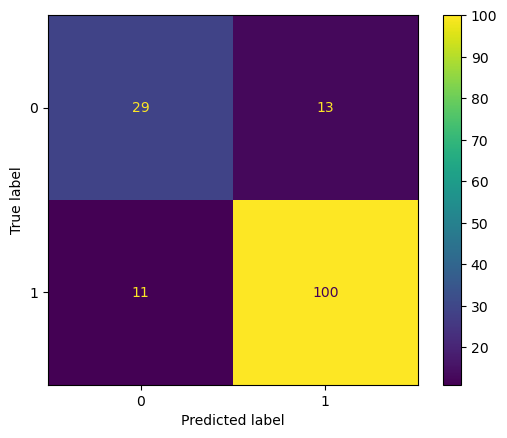

In [57]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

test_pred = (
    test_probs >= best_threshold
).astype(int)

cm = confusion_matrix(
    y_test,
    test_pred
)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm
).plot()

In [58]:
tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn)

specificity = tn / (tn + fp)

print(
    "Sensitivity:",
    sensitivity
)

print(
    "Specificity:",
    specificity
)

Sensitivity: 0.9009009009009009
Specificity: 0.6904761904761905


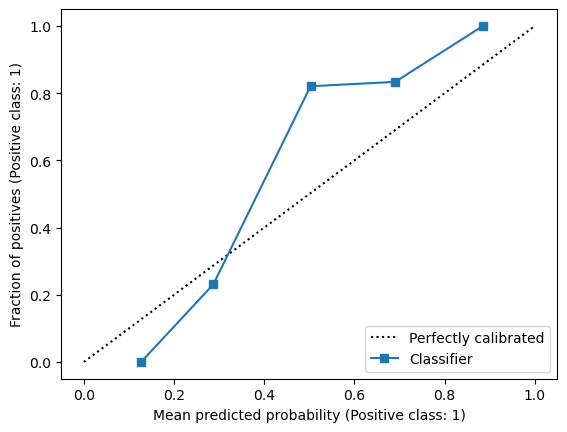

In [59]:
from sklearn.calibration import CalibrationDisplay
import matplotlib.pyplot as plt

CalibrationDisplay.from_predictions(
    y_test,
    test_probs
)

plt.show()

In [60]:
from sklearn.metrics import roc_auc_score
import numpy as np

subjects = groups_test.unique()

aucs = []

rng = np.random.RandomState(42)

for _ in range(1000):

    sampled_subjects = rng.choice(
        subjects,
        size=len(subjects),
        replace=True
    )

    mask = groups_test.isin(
        sampled_subjects
    )

    y_boot = y_test[mask]
    p_boot = test_probs[mask]

    if len(np.unique(y_boot)) < 2:
        continue

    aucs.append(
        roc_auc_score(
            y_boot,
            p_boot
        )
    )

lower = np.percentile(
    aucs,
    2.5
)

upper = np.percentile(
    aucs,
    97.5
)

print(
    "95% AUC CI:",
    (lower, upper)
)

95% AUC CI: (0.8208843434343435, 0.9542314009661835)


Q13.

I chose the threshold selected from the cross-validation predictions because it provided a good balance between identifying Parkinson's cases and limiting false positives. For a screening tool, missing a person with Parkinson's disease is generally more costly than flagging a healthy person for additional testing, so a higher sensitivity is preferred. Using this threshold, the model achieved a sensitivity of 90.1% and a specificity of 69.0%. The confusion matrix showed 100 true positives, 29 true negatives, 13 false positives, and 11 false negatives. Class weighting changes how the model learns during training by giving more importance to the minority class, while moving the threshold changes the final classification decision without retraining the model.

Q14.

The test AUC appears consistent with the nested cross-validation estimate because the bootstrap 95% confidence interval of (0.821, 0.954) includes the nested CV estimate of about 0.823. This suggests that the model's test performance is reasonably aligned with what was expected from validation. However, the confidence interval is fairly wide, which means there is still uncertainty due to the limited number of subjects. I would be cautious about placing too much trust in the exact point estimate and would focus on the interval as a whole. I would not show raw predicted probabilities to a clinician without calibration information, because predicted probabilities may not perfectly reflect true risk even when the model has good discrimination.